In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator

import json
import pickle
import torch

from scipy.stats import wilcoxon

# Compare best base models with FoMo-0D

24.10. model_24_10: SquareGMM of Simon, feat=70, inflate_full=True, delta=0.005, max_feature_dim=70, max_model_dim=70, prior.gmm.max_num_cluster=70, EPOCHS=50, BATCH_SIZE=6, nlayer=6, nhead=2,

---> BEST MODEL: model_24_10

In [2]:
#Fomo-0D model
default_dir = "../results/adbench/context5000.feat100.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
default_dir_best_loss = "../ckpt/context5000.feat100.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/seed0/best.ckpt"

model_24_10_dir = "../results/adbench/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/train_seed=0.transform=quantile.feat_truncation=subsampling"

model_24_10_train_val_loss_dir = "../ckpt/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/train_val_loss.pickle"
model_24_10_best_dir = "../ckpt/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/best.ckpt"
model_24_10_best_val_dir = "../ckpt/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/best_val.ckpt"
model_24_10_last_dir = "../ckpt/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/last.ckpt"



### 1. Default model

In [3]:
default_aucroc_scores = []
default_aucpr_scores = []
default_f1_scores = []
datasets_name = []
default_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(default_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # extract scores
        aucroc = df['aucroc'].values[0]
        default_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        default_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        default_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        default_time_per_instance.append(time_instance)

# compute average scores of all datasets
default_avg_aucroc = sum(default_aucroc_scores) / len(default_aucroc_scores)
default_avg_aucpr = sum(default_aucpr_scores) / len(default_aucpr_scores)
default_avg_f1 = sum(default_f1_scores) / len(default_f1_scores)
default_time_per_instance_avg = sum(default_time_per_instance) / len(default_time_per_instance)

print(f"number of datasets: {len(default_aucroc_scores)}")
print(f"Average aucroc: {default_avg_aucroc}")
print(f"Average aucpr: {default_avg_aucpr}")
print(f"Average f1: {default_avg_f1}")
print(f"Inference time per instance: {default_time_per_instance_avg}")

number of datasets: 121
Average aucroc: 0.7590645511541744
Average aucpr: 0.4786638498057685
Average f1: 0.4666975187169514
Inference time per instance: 0.004876898293420036


In [4]:
default_fomo_dict = {'dataset': datasets_name, 'aucroc': default_aucroc_scores, 'aucpr': default_aucpr_scores, 'f1': default_f1_scores}
default_fomo_df = pd.DataFrame(default_fomo_dict)
#default_fomo_df.to_csv('default_fomo_result.csv')

In [5]:
default_ckpt_best = torch.load(default_dir_best_loss, map_location="cpu")

default_train_loss = default_ckpt_best["train_losses"]
default_val_loss = default_ckpt_best["val_losses"]
default_last_lr = default_ckpt_best["lr_schedulers"][0]['_last_lr']

print(default_ckpt_best.keys())
print(default_ckpt_best["epoch"])


dict_keys(['epoch', 'global_step', 'pytorch-lightning_version', 'state_dict', 'loops', 'callbacks', 'optimizer_states', 'lr_schedulers', 'train_losses', 'val_losses'])
176


### 2. model_24_10 (best model)

In [6]:
with open(model_24_10_train_val_loss_dir, "rb") as f:
    data = pickle.load(f)

train_loss_24_10 = data["train_loss"]
val_loss_24_10 = data["val_loss"]
model_24_10_train_time = data['train_time']

print("Train time in second", model_24_10_train_time)

model_24_10_aucroc_scores = []
model_24_10_aucpr_scores = []
model_24_10_f1_scores = []
datasets_name = []
model_24_10_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_24_10_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)
        
        # extract scores
        aucroc = df['aucroc'].values[0]
        model_24_10_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_24_10_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_24_10_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_24_10_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_24_10_avg_aucroc = sum(model_24_10_aucroc_scores) / len(model_24_10_aucroc_scores)
model_24_10_avg_aucpr = sum(model_24_10_aucpr_scores) / len(model_24_10_aucpr_scores)
model_24_10_avg_f1 = sum(model_24_10_f1_scores) / len(model_24_10_f1_scores)
model_24_10_time_per_instance_avg = sum(model_24_10_time_per_instance) / len(model_24_10_time_per_instance)

print(f"number of datasets: {len(model_24_10_aucroc_scores)}")
print(f"Average aucroc: {model_24_10_avg_aucroc}")
print(f"Average aucpr: {model_24_10_avg_aucpr}")
print(f"Average f1: {model_24_10_avg_f1}")
print(f"Inference time per instance: {model_24_10_time_per_instance_avg}")

Train time in second 24182.45950436592
number of datasets: 121
Average aucroc: 0.7761609876983426
Average aucpr: 0.4592854784870678
Average f1: 0.46209364279753334
Inference time per instance: 7.158595120994333e-06


In [7]:
model_24_10_dict = {'dataset': datasets_name, 'aucroc': model_24_10_aucroc_scores, 'aucpr': model_24_10_aucpr_scores, 'f1': model_24_10_f1_scores}
model_24_10_df = pd.DataFrame(model_24_10_dict)
#model_24_10_df.to_csv('model_24_10_result.csv')

### Scatter plot of two models:

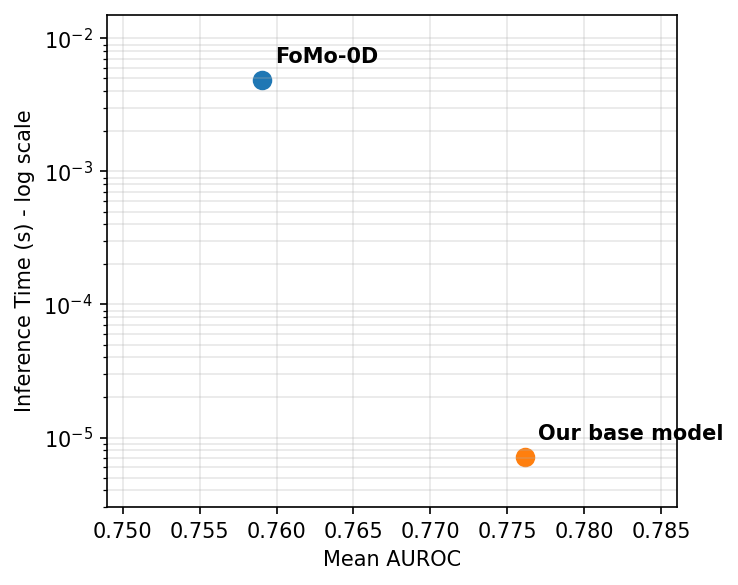

In [8]:
models = [
    ("FoMo-0D", 0.7590645511541744, 0.004876898293420036),
    ("Our base model", 0.7761609876983426, 7.158595120994333e-06),
]

fig, ax = plt.subplots(figsize=(5, 4), dpi=150)

# Scatter points
for name, auc, infer_time in models:
    ax.scatter(auc, infer_time, s=70)
    ax.annotate(
        name,
        (auc, infer_time),
        xytext=(6, 8),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xlabel("Mean AUROC")
ax.set_ylabel("Inference Time (s) - log scale")
ax.set_yscale("log")
#ax.set_title("Model Comparison", fontsize=16, fontweight="bold")
ax.grid(True, which="both", alpha=0.3)

ax.set_xlim(0.749, 0.786)
ax.set_ylim(3e-6, 1.5e-2)
#ax.legend(['#features=100, #epochs=200, #batch=8', 'test'])

plt.tight_layout()

#plt.savefig('fomo_best_model_auroc.png', dpi=300, bbox_inches='tight')
plt.show()

### P-value of default_fomo and model_24_10(best_model)  (over 121 datasets)

In [9]:
model_24_10_result = pd.read_csv('model_24_10_result.csv')
default_fomo_result = pd.read_csv('default_fomo_result.csv')

In [10]:
import numpy as np
from scipy.stats import wilcoxon
model_24_10_auc, default_fomo_auc = [], []
for ds, auc, default in zip(model_24_10_result["dataset"],model_24_10_result["aucroc"], default_fomo_result['aucroc']):
    model_24_10_auc.append(auc)
    default_fomo_auc.append(default)

model_24_10_auc = np.array(model_24_10_auc)
default_fomo_auc = np.array(default_fomo_auc)

# Check differences
diffs = model_24_10_auc - default_fomo_auc
print("Mean improvement:", np.mean(diffs))
print("Better ratio:", np.mean(diffs > 0))

# One-sided Wilcoxon test
stat, p_value = wilcoxon(model_24_10_auc, default_fomo_auc, alternative='greater')

print("Statistic:", stat)
print("p-value:", p_value)
print(f"mean value of mode_24_10 vs. fomo-0D: {np.mean(model_24_10_auc)} vs. {np.mean(default_fomo_auc)}")  

Mean improvement: 0.017096436544167908
Better ratio: 0.4628099173553719
Statistic: 3996.0
p-value: 0.09615333781230967
mean value of mode_24_10 vs. fomo-0D: 0.7761609876983423 vs. 0.7590645511541743


The model shows a small average improvement in AUC (+0.017) and outperforms the baseline on 58% of datasets. However, the difference is not statistically significant (Wilcoxon signed-rank test, p = 0.127)

In [11]:
# # new files:
# model_24_10_result = pd.read_csv('processed_model_24_10_results.csv')
# default_fomo_result = pd.read_csv('processed_default_fomo.csv')

# model_24_10_auc, default_fomo_auc = [], []
# for ds, auc, default in zip(model_24_10_result["dataset"],model_24_10_result["aucroc"], default_fomo_result['aucroc']):
#     model_24_10_auc.append(auc)
#     default_fomo_auc.append(default)

# model_24_10_auc = np.array(model_24_10_auc)
# default_fomo_auc = np.array(default_fomo_auc)

# # Check differences
# diffs = model_24_10_auc - default_fomo_auc
# print("Mean improvement:", np.mean(diffs))
# print("Better ratio:", np.mean(diffs > 0))

# # One-sided Wilcoxon test
# stat, p_value = wilcoxon(model_24_10_auc, default_fomo_auc, alternative='greater')

# print("Statistic:", stat)
# print("p-value:", p_value)

### Compare against some high dimensional datasets

In [12]:
# Image
CIFAR10 = ['CIFAR10_0', 'CIFAR10_1', 'CIFAR10_2', 'CIFAR10_3', 'CIFAR10_4', 'CIFAR10_5', 'CIFAR10_6', 'CIFAR10_7', 'CIFAR10_8', 'CIFAR10_9']
FashionMNIST = ['FashionMNIST_0', 'FashionMNIST_1', 'FashionMNIST_2', 'FashionMNIST_3', 'FashionMNIST_4', 'FashionMNIST_5', 'FashionMNIST_6', 'FashionMNIST_7', 'FashionMNIST_8', 'FashionMNIST_9']
MNIST_C = ['MNIST-C_brightness', 'MNIST-C_canny_edges', 'MNIST-C_dotted_line', 'MNIST-C_fog', 'MNIST-C_glass_blur', 'MNIST-C_identity', 
           'MNIST-C_impulse_noise', 'MNIST-C_motion_blur', 'MNIST-C_rotate', 'MNIST-C_scale', 'MNIST-C_shear', 'MNIST-C_shot_noise', 
           'MNIST-C_spatter', 'MNIST-C_stripe', 'MNIST-C_translate', 'MNIST-C_zigzag']
MVTec_AD = ['MVTec-AD_bottle', 'MVTec-AD_cable', 'MVTec-AD_capsule', 'MVTec-AD_carpet', 'MVTec-AD_grid', 'MVTec-AD_hazelnut', 'MVTec-AD_leather', 
            'MVTec-AD_metal_nut', 'MVTec-AD_pill', 'MVTec-AD_screw', 'MVTec-AD_tile', 'MVTec-AD_toothbrush', 'MVTec-AD_transistor', 'MVTec-AD_wood', 'MVTec-AD_zipper']

SVHN = ['SVHN_0', 'SVHN_1', 'SVHN_2', 'SVHN_3', 'SVHN_4', 'SVHN_5', 'SVHN_6', 'SVHN_7', 'SVHN_8', 'SVHN_9']

In [13]:
# NLP
agnews = ['agnews_0', 'agnews_1', 'agnews_2', 'agnews_3']
amazon = ['amazon']
Imdb = ['imdb']
Yelp = ['yelp']
test_20newsgroups = ['20news_0', '20news_1', '20news_2', '20news_3', '20news_4', '20news_5']

### Group Image

##### 1. CIFAR10

In [14]:
default_CIFAR10 = []
base_model_CIFAR10 = []
for item in CIFAR10:
    default_CIFAR10.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_CIFAR10.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

CIFAR10_dict = {'dataset': CIFAR10, 'default_CIFAR10': default_CIFAR10, 'model_24_10_CIFAR10': base_model_CIFAR10}
CIFAR10_df = pd.DataFrame(CIFAR10_dict)
CIFAR10_df

,dataset,default_CIFAR10,model_24_10_CIFAR10
0,CIFAR10_0,0.724511,0.695703
1,CIFAR10_1,0.621957,0.607942
2,CIFAR10_2,0.607141,0.569700
3,CIFAR10_3,0.546823,0.502456
4,CIFAR10_4,0.679700,0.678649
5,CIFAR10_5,0.552525,0.488569
6,CIFAR10_6,0.683488,0.620563
7,CIFAR10_7,0.612274,0.606864
8,CIFAR10_8,0.704944,0.674608
9,CIFAR10_9,0.701357,0.710367


##### 2. FashionMNIST

In [15]:
default_FashionMNIST = []
base_model_FashionMNIST = []
for item in FashionMNIST:
    default_FashionMNIST.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_FashionMNIST.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

FashionMNIST_dict = {'dataset': FashionMNIST, 'default_FashionMNIST': default_FashionMNIST, 'model_24_10_FashionMNIST': base_model_FashionMNIST}
FashionMNIST_df = pd.DataFrame(FashionMNIST_dict)
FashionMNIST_df

,dataset,default_FashionMNIST,model_24_10_FashionMNIST
0,FashionMNIST_0,0.864314,0.833210
1,FashionMNIST_1,0.934321,0.886491
2,FashionMNIST_2,0.840391,0.730387
3,FashionMNIST_3,0.856535,0.855387
4,FashionMNIST_4,0.838874,0.786421
5,FashionMNIST_5,0.924911,0.918876
6,FashionMNIST_6,0.731300,0.712177
7,FashionMNIST_7,0.936253,0.907375
8,FashionMNIST_8,0.842901,0.850037
9,FashionMNIST_9,0.958121,0.943699


##### 3. MNIST_C

In [16]:
default_MNIST_C = []
base_model_MNIST_C = []
for item in MNIST_C:
    default_MNIST_C.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_MNIST_C.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

MNIST_C_dict = {'dataset': MNIST_C, 'default_MNIST_C': default_MNIST_C, 'model_24_10_MNIST_C': base_model_MNIST_C}
MNIST_C_df = pd.DataFrame(MNIST_C_dict)
MNIST_C_df

,dataset,default_MNIST_C,model_24_10_MNIST_C
0,MNIST-C_brightness,0.732662,0.815336
1,MNIST-C_canny_edges,0.838866,0.849418
2,MNIST-C_dotted_line,0.795969,0.764500
3,MNIST-C_fog,0.937361,0.946931
4,MNIST-C_glass_blur,0.946622,0.902214
5,MNIST-C_identity,0.470528,0.482561
6,MNIST-C_impulse_noise,0.999925,0.995048
7,MNIST-C_motion_blur,0.819526,0.879562
8,MNIST-C_rotate,0.547304,0.598710
9,MNIST-C_scale,0.694694,0.883920


##### 4. MVTec_AD

In [17]:
default_MVTec_AD = []
base_model_MVTec_AD = []
for item in MVTec_AD:
    default_MVTec_AD.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_MVTec_AD.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

MVTec_AD_dict = {'dataset': MVTec_AD, 'default_MVTec_AD': default_MVTec_AD, 'model_24_10_MVTec_AD': base_model_MVTec_AD}
MVTec_AD_df = pd.DataFrame(MVTec_AD_dict)
MVTec_AD_df

,dataset,default_MVTec_AD,model_24_10_MVTec_AD
0,MVTec-AD_bottle,0.971409,0.996197
1,MVTec-AD_cable,0.716171,0.939546
2,MVTec-AD_capsule,0.613014,0.827005
3,MVTec-AD_carpet,0.718359,0.871997
4,MVTec-AD_grid,0.658397,0.888249
5,MVTec-AD_hazelnut,0.644551,0.859767
6,MVTec-AD_leather,0.968578,0.963761
7,MVTec-AD_metal_nut,0.780553,0.852451
8,MVTec-AD_pill,0.762669,0.872589
9,MVTec-AD_screw,0.521039,0.738385


##### 5. SVHN

In [18]:
default_SVHN = []
base_model_SVHN = []
for item in SVHN:
    default_SVHN.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_SVHN.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

SVHN_dict = {'dataset': SVHN, 'default_SVHN': default_SVHN, 'model_24_10_SVHN': base_model_SVHN}
SVHN_df = pd.DataFrame(SVHN_dict)
SVHN_df

,dataset,default_SVHN,model_24_10_SVHN
0,SVHN_0,0.575946,0.536363
1,SVHN_1,0.595887,0.534543
2,SVHN_2,0.640147,0.636998
3,SVHN_3,0.616290,0.652900
4,SVHN_4,0.587366,0.618327
5,SVHN_5,0.661108,0.672675
6,SVHN_6,0.540792,0.559945
7,SVHN_7,0.594488,0.598566
8,SVHN_8,0.563458,0.578180
9,SVHN_9,0.568964,0.543195


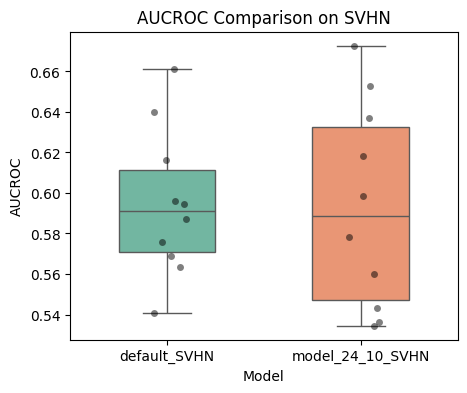

In [19]:
SVHN_melted = SVHN_df.melt(
    id_vars='dataset',
    value_vars=['default_SVHN', 'model_24_10_SVHN'],
    var_name='model',
    value_name='aucroc'
)
plt.figure(figsize=(5, 4))
#sns.boxplot(data=SVHN_melted, x='model', y='aucroc')
sns.boxplot(data=SVHN_melted, x='model', y='aucroc', hue="model", palette="Set2", legend='auto', width=0.5)
sns.stripplot(data=SVHN_melted, x='model', y='aucroc', color='black', alpha=0.5)

plt.title('AUCROC Comparison on SVHN')
plt.xlabel('Model')
plt.ylabel('AUCROC')

plt.show()
#plt.savefig('data_priors_impact.png', dpi=300, bbox_inches='tight')

In [20]:
# Add a column telling which dataset-group each dataframe belongs to
CIFAR10_plot = CIFAR10_df.rename(columns={
    'default_CIFAR10': 'FoMo-0D',
    'model_24_10_CIFAR10': 'Our base model'
}).copy()
CIFAR10_plot['group'] = 'CIFAR10'

FashionMNIST_plot = FashionMNIST_df.rename(columns={
    'default_FashionMNIST': 'FoMo-0D',
    'model_24_10_FashionMNIST': 'Our base model'
}).copy()
FashionMNIST_plot['group'] = 'FashionMNIST'

MNIST_C_plot = MNIST_C_df.rename(columns={
    'default_MNIST_C': 'FoMo-0D',
    'model_24_10_MNIST_C': 'Our base model'
}).copy()
MNIST_C_plot['group'] = 'MNIST_C'

MVTec_AD_plot = MVTec_AD_df.rename(columns={
    'default_MVTec_AD': 'FoMo-0D',
    'model_24_10_MVTec_AD': 'Our base model'
}).copy()
MVTec_AD_plot['group'] = 'MVTec_AD'

SVHN_plot = SVHN_df.rename(columns={
    'default_SVHN': 'FoMo-0D',
    'model_24_10_SVHN': 'Our base model'
}).copy()
SVHN_plot['group'] = 'SVHN'

# Combine all 5 dataframes
all_df = pd.concat(
    [CIFAR10_plot, FashionMNIST_plot, MNIST_C_plot, MVTec_AD_plot, SVHN_plot],
    ignore_index=True
)

# Convert from wide to long format
plot_df = all_df.melt(
    id_vars=['dataset', 'group'],
    value_vars=['FoMo-0D', 'Our base model'],
    var_name='model',
    value_name='aucroc'
)



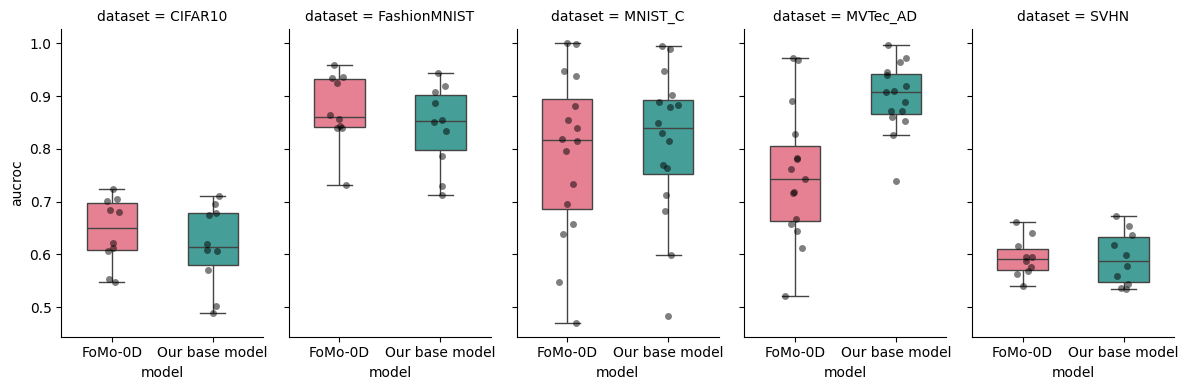

In [21]:
#plt.figure(figsize=(10, 5))
g = sns.catplot(
    data=plot_df,
    x='model',
    y='aucroc',
    col='group',
    kind='box',
    hue='model', palette="husl", legend='auto', width=0.5,
    col_wrap=5,
    height=4,
    aspect=0.6,
    showfliers=False
)

# Add points on top of each facet
g.map_dataframe(
    sns.stripplot,
    x='model',
    y='aucroc',
    color='black',
    alpha=0.5,
    jitter=True
)

g.set_axis_labels("model", "aucroc")
g.set_titles("dataset = {col_name}")
#g.fig.set_size_inches(16, 4)
#plt.savefig('image_datasets_fomo_best_model.png', dpi=300, bbox_inches='tight')
plt.show()

### group NLP

##### 1. agnews

In [22]:
default_agnews = []
base_model_agnews = []
for item in agnews:
    default_agnews.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_agnews.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

agnews_dict = {'dataset': agnews, 'default_agnews': default_agnews, 'model_24_10_agnews': base_model_agnews}
agnews_df = pd.DataFrame(agnews_dict)
agnews_df


,dataset,default_agnews,model_24_10_agnews
0,agnews_0,0.578405,0.608261
1,agnews_1,0.587309,0.716865
2,agnews_2,0.702509,0.766122
3,agnews_3,0.568240,0.675795


##### 2. amazon

In [23]:
default_amazon = []
base_model_amazon = []
for item in amazon:
    default_amazon.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_amazon.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

amazon_dict = {'dataset': amazon, 'default_amazon': default_amazon, 'model_24_10_amazon': base_model_amazon}
amazon_df = pd.DataFrame(amazon_dict)
amazon_df

,dataset,default_amazon,model_24_10_amazon
0,amazon,0.49657,0.548579


##### 3. Imdb

In [24]:
default_imdb = []
base_model_imdb = []
for item in Imdb:
    default_imdb.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_imdb.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

imdb_dict = {'dataset': Imdb, 'default_imdb': default_imdb, 'model_24_10_imdb': base_model_imdb}
imdb_df = pd.DataFrame(imdb_dict)
imdb_df

,dataset,default_imdb,model_24_10_imdb
0,imdb,0.446315,0.489552


##### 4. yelp

In [25]:
default_yelp = []
base_model_yelp = []
for item in Yelp:
    default_yelp.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_yelp.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

yelp_dict = {'dataset': Yelp, 'default_yelp': default_yelp, 'model_24_10_yelp': base_model_yelp}
yelp_df = pd.DataFrame(yelp_dict)
yelp_df

,dataset,default_yelp,model_24_10_yelp
0,yelp,0.571992,0.643195


##### 2. 20newsgroups

In [26]:
default_20newsgroups = []
base_model_20newsgroups = []
for item in test_20newsgroups:
    default_20newsgroups.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_20newsgroups.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

test_20newsgroups_dict = {'dataset': test_20newsgroups, 'default_20newsgroups': default_20newsgroups, 'model_24_10_20newsgroups': base_model_20newsgroups}
test_20newsgroups_df = pd.DataFrame(test_20newsgroups_dict)
test_20newsgroups_df

,dataset,default_20newsgroups,model_24_10_20newsgroups
0,20news_0,0.643426,0.746532
1,20news_1,0.510875,0.515474
2,20news_2,0.514481,0.501631
3,20news_3,0.773958,0.832611
4,20news_4,0.582282,0.560743
5,20news_5,0.531051,0.538733


In [27]:
# Add a column telling which dataset-group each dataframe belongs to
agnews_plot = agnews_df.rename(columns={
    'default_agnews': 'FoMo-0D',
    'model_24_10_agnews': 'Our base model'
}).copy()
agnews_plot['group'] = 'Agnews'

amazon_plot = amazon_df.rename(columns={
    'default_amazon': 'FoMo-0D',
    'model_24_10_amazon': 'Our base model'
}).copy()
amazon_plot['group'] = 'Amazon'

imdb_plot = imdb_df.rename(columns={
    'default_imdb': 'FoMo-0D',
    'model_24_10_imdb': 'Our base model'
}).copy()
imdb_plot['group'] = 'Imdb'

yelp_plot = yelp_df.rename(columns={
    'default_yelp': 'FoMo-0D',
    'model_24_10_yelp': 'Our base model'
}).copy()
yelp_plot['group'] = 'Yelp'

test_20newsgroups_plot = test_20newsgroups_df.rename(columns={
    'default_20newsgroups': 'FoMo-0D',
    'model_24_10_20newsgroups': 'Our base model'
}).copy()
test_20newsgroups_plot['group'] = '20newsgroups'

# Combine all 5 dataframes
all_df = pd.concat(
    [agnews_plot, amazon_plot, imdb_plot, yelp_plot, test_20newsgroups_plot],
    ignore_index=True
)

# Convert from wide to long format
plot_df = all_df.melt(
    id_vars=['dataset', 'group'],
    value_vars=['FoMo-0D', 'Our base model'],
    var_name='model',
    value_name='aucroc'
)

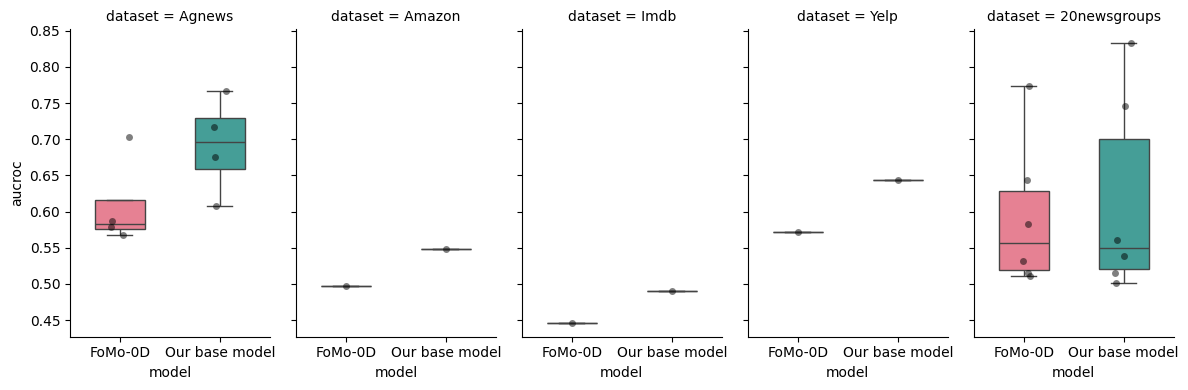

In [28]:
g = sns.catplot(
    data=plot_df,
    x='model',
    y='aucroc',
    col='group',
    kind='box',
    hue='model', palette="husl", legend='auto', width=0.5,
    col_wrap=5,
    height=4,
    aspect=0.6,
    showfliers=False
)

# Add points on top of each facet
g.map_dataframe(
    sns.stripplot,
    x='model',
    y='aucroc',
    color='black',
    alpha=0.5,
    jitter=True
)

g.set_axis_labels("model", "aucroc")
g.set_titles("dataset = {col_name}")
#g.fig.set_size_inches(16, 4)
#plt.savefig('nlp_datasets_fomo_best_model.png', dpi=300, bbox_inches='tight')
plt.show()

In [29]:
model_24_10_result = pd.read_csv('processed_model_24_10_results.csv')
default_fomo_result = pd.read_csv('processed_default_fomo.csv')
default_fomo_result

,dataset,aucroc,aucpr,f1
0,10_cover,0.995771,0.832397,0.812500
1,11_donors,0.999171,0.982307,0.987276
2,12_fault,0.618193,0.630824,0.575037
3,13_fraud,0.958225,0.698304,0.760870
4,14_glass,0.979874,0.898509,0.760000
5,15_Hepatitis,1.000000,1.000000,1.000000
6,16_http,0.999456,0.933672,0.928571
7,17_InternetAds,0.615096,0.409273,0.491848
8,18_Ionosphere,0.953658,0.969514,0.923304
9,19_landsat,0.695331,0.582359,0.526632


In [30]:
datasets_10 = ['CIFAR10', 'FashionMNIST', 'MNIST-C', 'MVTec-AD', 'SVHN', 'agnews', 'amazon', 'imdb', 'yelp', '20news']
model_24 = []
default_model = []
for item in datasets_10:
    model_24.append(model_24_10_result[model_24_10_result['dataset'] == item]['aucroc'].values[0])
    default_model.append(default_fomo_result[default_fomo_result['dataset'] == item]['aucroc'].values[0])

dict_df = {'dataset':datasets_10, 'model_24': model_24, 'default': default_model}

In [31]:
df = pd.DataFrame(dict_df)
df

,dataset,model_24,default
0,CIFAR10,0.615542,0.643472
1,FashionMNIST,0.842406,0.872792
2,MNIST-C,0.811897,0.789468
3,MVTec-AD,0.897453,0.751019
4,SVHN,0.593169,0.594444
5,agnews,0.691760,0.609116
6,amazon,0.548579,0.496570
7,imdb,0.489552,0.446315
8,yelp,0.643195,0.571992
9,20news,0.615954,0.592679
